# Semantic Backup Layer: Closing the Validation Gap

This is the notebook the paper's Section 7 points at: the semantic backup
layer is architecturally implemented and integration-tested, but its
**actual job** -- separating genuinely-novel-correct submissions from
genuinely-wrong ones -- has never been empirically tested. This notebook
does that, honestly, and reports the result either way.

**What "honestly" means here, concretely, based on lessons already learned
in earlier attempts at this exact question:**

- **Real embeddings, not a stand-in.** The original sandboxed attempt used a
  bag-of-AST-tokens stub with no discriminative power, and a first real
  attempt with raw `codebert-base` reproduced that same failure for a
  different reason (anisotropy). This notebook uses
  `Salesforce/codet5p-110m-embedding`, already confirmed to produce a real,
  usable separation between related and unrelated code.
- **A real exemplar registry, not 2-3 hand-written snippets.** Built from
  actual diverse correct Refactory submissions, not one canonical style.
- **A real, uncontaminated comparison group.** An earlier attempt at this
  exact experiment used "wrong-labeled submissions that also score 0
  structurally" as the negative class, and got a suspiciously high, tight
  similarity score for the negative group -- traced to contamination: most
  wrong-labeled submissions in this dataset still correctly implement the
  target pattern and fail elsewhere, so restricting to "also 0 structurally"
  was accidentally selecting for submissions that already look similar to
  correct code. This notebook uses ALL wrong-labeled submissions as the
  negative class instead, the same fix applied there.
- **Robustness, not a single run.** Every embeddings check done so far in
  this project turned out to have real seed-to-seed variance. This notebook
  bootstraps the exemplar registry itself (which exemplars are drawn) across
  multiple runs and reports a mean +/- spread on the separation metric (AUC),
  not one number from one draw.

**Default competency: FindExtremum (Q5, Top-K).** This is the one with an
already-confirmed, reasonably-sized novel-correct population (43 real
candidates found earlier) to test against. The code is written to be easy
to re-point at a different competency/exercise -- see the CONFIG cell.


## 1. Setup

In [ ]:
!pip install -q transformers torch pandas scikit-learn matplotlib

import torch
print("CUDA available:", torch.cuda.is_available())
print("Device:", "cuda" if torch.cuda.is_available() else "cpu (fine for codet5p-110m-embedding on short snippets)")


CUDA available: True
Device: cuda


## 2. Mount Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT_DIR = '/content/drive/MyDrive/competency_extraction'  # <-- adjust if needed

import os
assert os.path.isdir(PROJECT_DIR), f"Not found: {PROJECT_DIR} -- check the folder name/path in Drive"
print("Contents:", os.listdir(PROJECT_DIR))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Contents: ['competency.py', 'semantic_backup.py', 'data', '.ipynb_checkpoints', 'q2_report.csv', 'q4_report.csv', 'ast_taxo_cross_Res_Q5', 'q4_embeddings_crossvalidation.csv', 'q2_embeddings_crossvalidation.csv', 'topk_report.csv']


## 3. Configuration

Everything competency-specific lives here. To re-run this for a different
exercise (e.g. Q4/SortByKey instead of Q5/FindExtremum), only this cell
should need to change.


In [ ]:
COMPETENCY = "FindExtremum"          # the _final column in the batch report to test against
BATCH_REPORT_CSV = f"{PROJECT_DIR}/topk_report.csv"
DATA_FOLDER = f"{PROJECT_DIR}/data/question_5/code"   # has correct/ and wrong/ subfolders

N_EXEMPLARS = 8            # real correct submissions pulled into the registry
N_BOOTSTRAP_RUNS = 10       # how many different exemplar draws to test robustness across
RANDOM_SEED_BASE = 0


## 4. Load the embedding model

`codet5p-110m-embedding`, with the config patch for the `is_decoder`
compatibility bug (no `transformers` version pin needed -- see the other
notebooks in this project for why the version-pin approach was abandoned).


In [ ]:
from transformers import AutoConfig, AutoModel, AutoTokenizer
import torch

_checkpoint = "Salesforce/codet5p-110m-embedding"
_device = "cuda" if torch.cuda.is_available() else "cpu"

_tokenizer = AutoTokenizer.from_pretrained(_checkpoint, trust_remote_code=True)

_config = AutoConfig.from_pretrained(_checkpoint, trust_remote_code=True)
for _attr, _default in [("is_decoder", False), ("is_encoder_decoder", True),
                         ("pad_token_id", 0), ("eos_token_id", 2)]:
    if not hasattr(_config, _attr):
        setattr(_config, _attr, _default)

_model = AutoModel.from_pretrained(_checkpoint, config=_config, trust_remote_code=True).to(_device)
_model.eval()

@torch.no_grad()
def embed(code: str):
    inputs = _tokenizer.encode(code, return_tensors="pt", truncation=True, max_length=512).to(_device)
    embedding = _model(inputs)[0]  # already L2-normalized
    return embedding.cpu().numpy()

def cosine_sim(a, b) -> float:
    import numpy as np
    return float(np.dot(a, b))

related_a = "def f(lst):\n    best = lst[0]\n    for x in lst:\n        if x > best:\n            best = x\n    return best"
related_b = "def f(lst):\n    return max(lst)"
unrelated  = "def greet(name):\n    return 'Hello, ' + name"
print("related vs related:", cosine_sim(embed(related_a), embed(related_b)))
print("related vs unrelated:", cosine_sim(embed(related_a), embed(unrelated)))


config.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

configuration_codet5p_embedding.py:   0%|          | 0.00/2.62k [00:00<?, ?B/s]

[transformers] A new version of the following files was downloaded from https://huggingface.co/Salesforce/codet5p-110m-embedding:
- configuration_codet5p_embedding.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


tokenizer_config.json:   0%|          | 0.00/1.34k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/511k [00:00<?, ?B/s]

...

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  439MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] `use_return_dict` is deprecated! Use `return_dict` instead!


related vs related: 0.8398723602294922
related vs unrelated: 0.3819599151611328


## 5. Build the two real test groups

**novel_correct**: test-suite-correct, but scored 0 on the target
competency -- the layer's actual target population.

**genuinely_wrong**: ALL wrong-labeled submissions (not filtered to
"also 0 structurally" -- see the framing note in Section 1 for why that
filter contaminates the comparison).


In [ ]:
import pandas as pd

report = pd.read_csv(BATCH_REPORT_CSV)
report[f"{COMPETENCY}_final"] = pd.to_numeric(report[f"{COMPETENCY}_final"], errors="coerce")

novel_correct = report[
    (report["label"] == "correct") &
    (report[f"{COMPETENCY}_final"] == 0)
]
genuinely_wrong = report[
    report["label"] == "wrong"
]

print(f"novel_correct candidates: {len(novel_correct)}")
print(f"genuinely_wrong (all wrong-labeled): {len(genuinely_wrong)}")


novel_correct candidates: 43
genuinely_wrong (all wrong-labeled): 108


## 6. Read source helper


In [ ]:
import os

def read_src(fname):
    for sub in ["correct", "wrong"]:
        p = f"{DATA_FOLDER}/{sub}/{fname}"
        if os.path.exists(p):
            return open(p, encoding="utf-8").read()
    return None


## 7. Bootstrap: build a real exemplar registry, multiple times

Each run draws a fresh random set of `N_EXEMPLARS` real correct submissions
(held out from `novel_correct` scoring, so the registry never contains the
files being tested against it), builds their embeddings, then scores every
`novel_correct` and `genuinely_wrong` submission by its max similarity to
any exemplar. Repeating this across several draws, rather than trusting one
registry, is the same robustness lesson already learned from the taxonomy
cross-validation work -- a single draw's AUC can look better or worse than
what's actually typical.


In [ ]:
import numpy as np
import random
from sklearn.metrics import roc_auc_score, roc_curve

# Pool of correct submissions eligible to become exemplars: correct-labeled
# AND NOT already in novel_correct (an exemplar should be a "textbook"
# example the target competency DOES match, not one of the novel cases
# being tested).
exemplar_pool = report[
    (report["label"] == "correct") &
    (report[f"{COMPETENCY}_final"] >= 0.999)
]["file"].tolist()
print(f"eligible exemplar pool: {len(exemplar_pool)} files")

# Pre-embed every file that could possibly be needed, once, so the
# bootstrap loop below only does cheap resampling + cosine similarity,
# not repeated model calls.
all_needed_files = set(exemplar_pool) | set(novel_correct["file"]) | set(genuinely_wrong["file"])
embedding_cache = {}
for fname in all_needed_files:
    src = read_src(fname)
    if src is not None:
        embedding_cache[fname] = embed(src)

print(f"cached {len(embedding_cache)} of {len(all_needed_files)} needed files")


eligible exemplar pool: 375 files
cached 526 of 526 needed files


In [ ]:
def max_similarity_to_registry(fname, registry_embeddings):
    if fname not in embedding_cache:
        return None
    emb = embedding_cache[fname]
    return max(cosine_sim(emb, r) for r in registry_embeddings)

bootstrap_results = []
all_scores = []  # pooled (run, file, group, similarity) for later inspection

for run in range(N_BOOTSTRAP_RUNS):
    rng = random.Random(RANDOM_SEED_BASE + run)
    exemplar_files = rng.sample(exemplar_pool, min(N_EXEMPLARS, len(exemplar_pool)))
    registry_embeddings = [embedding_cache[f] for f in exemplar_files if f in embedding_cache]

    novel_scores, wrong_scores = [], []
    for fname in novel_correct["file"]:
        s = max_similarity_to_registry(fname, registry_embeddings)
        if s is not None:
            novel_scores.append(s)
            all_scores.append({"run": run, "file": fname, "group": "novel_correct", "similarity": s})
    for fname in genuinely_wrong["file"]:
        s = max_similarity_to_registry(fname, registry_embeddings)
        if s is not None:
            wrong_scores.append(s)
            all_scores.append({"run": run, "file": fname, "group": "genuinely_wrong", "similarity": s})

    y_true = [1] * len(novel_scores) + [0] * len(wrong_scores)
    y_score = novel_scores + wrong_scores
    auc = roc_auc_score(y_true, y_score) if len(set(y_true)) > 1 else float("nan")

    bootstrap_results.append({
        "run": run,
        "auc": auc,
        "novel_mean": np.mean(novel_scores), "novel_std": np.std(novel_scores),
        "wrong_mean": np.mean(wrong_scores), "wrong_std": np.std(wrong_scores),
        "n_novel": len(novel_scores), "n_wrong": len(wrong_scores),
    })

bootstrap_df = pd.DataFrame(bootstrap_results)
print(bootstrap_df)
print()
print(f"AUC: mean={bootstrap_df['auc'].mean():.3f}  std={bootstrap_df['auc'].std():.3f}  "
      f"(0.5 = no separation at all, 1.0 = perfect separation)")


   run       auc  novel_mean  novel_std  wrong_mean  wrong_std  n_novel  \
0    0  0.125754    0.810732   0.115731    0.950610   0.028609       43   
1    1  0.056202    0.805990   0.110988    0.954629   0.027528       43   
2    2  0.096899    0.794045   0.123072    0.950589   0.027592       43   
3    3  0.173342    0.810147   0.115905    0.942699   0.031810       43   
4    4  0.074720    0.796510   0.116748    0.951730   0.027068       43   
5    5  0.122524    0.811085   0.113171    0.951024   0.027687       43   
6    6  0.045650    0.797086   0.115645    0.956463   0.027530       43   
7    7  0.111972    0.806730   0.116518    0.953832   0.026619       43   
8    8  0.064169    0.795070   0.116356    0.954105   0.028467       43   
9    9  0.106158    0.796586   0.126860    0.951418   0.026873       43   

   n_wrong  
0      108  
1      108  
2      108  
3      108  
4      108  
5      108  
6      108  
7      108  
8      108  
9      108  

AUC: mean=0.098  std=0.039  (0

## 8. Read the result honestly

- **AUC well above 0.5, stable across runs** -> real, usable signal. The
  registry and threshold in Section 9 are worth deploying.
- **AUC near 0.5** -> the layer, as currently built, does not separate
  these two groups better than chance. That is a legitimate, reportable
  finding -- not a failure of this notebook, a finding about the approach.
- **AUC unstable across runs** (high std) -> whatever the mean says, treat
  it as inconclusive at this exemplar-registry size; report the instability
  itself as the finding, the same way Q2's counter/functional split turned
  out to be a sample-size limitation rather than a real result.


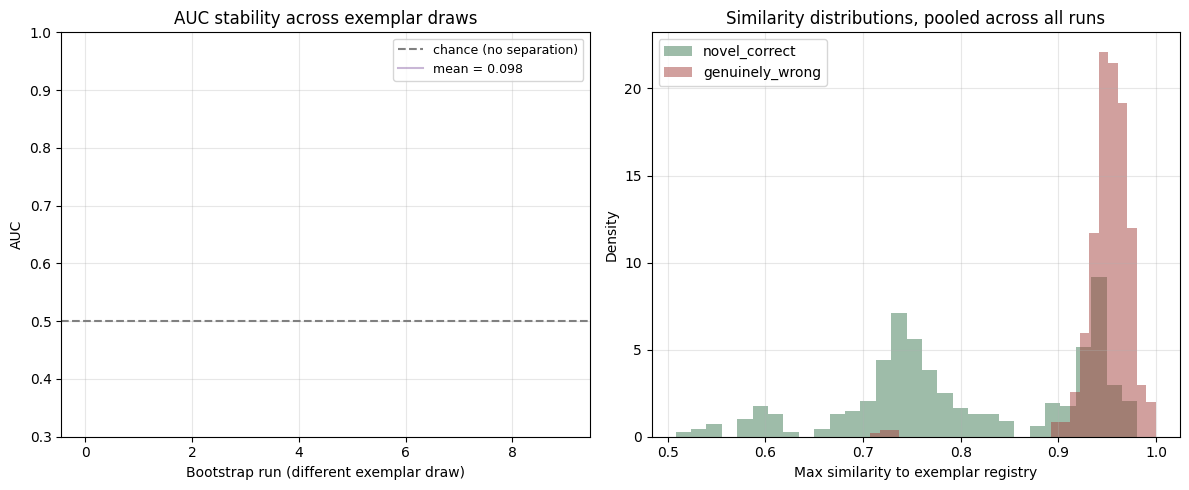

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(bootstrap_df["run"], bootstrap_df["auc"], marker="o", color="#7a4d99")
axes[0].axhline(0.5, color="gray", linestyle="--", label="chance (no separation)")
axes[0].axhline(bootstrap_df["auc"].mean(), color="#7a4d99", alpha=0.4,
                label=f"mean = {bootstrap_df['auc'].mean():.3f}")
axes[0].set_xlabel("Bootstrap run (different exemplar draw)")
axes[0].set_ylabel("AUC")
axes[0].set_ylim(0.3, 1.0)
axes[0].set_title("AUC stability across exemplar draws")
axes[0].legend(fontsize=9)
axes[0].grid(alpha=0.3)

pooled = pd.DataFrame(all_scores)
for group, color in [("novel_correct", "#3f7a54"), ("genuinely_wrong", "#a5423f")]:
    axes[1].hist(pooled[pooled["group"] == group]["similarity"], bins=30, alpha=0.5,
                 label=group, color=color, density=True)
axes[1].set_xlabel("Max similarity to exemplar registry")
axes[1].set_ylabel("Density")
axes[1].set_title("Similarity distributions, pooled across all runs")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f"{PROJECT_DIR}/semantic_backup_validation_result.png", dpi=200, bbox_inches="tight")
plt.show()


## 9. Threshold calibration (only meaningful if Section 8's AUC is genuinely good and stable)

Uses the pooled predictions across all bootstrap runs for a more stable
threshold estimate than any single run. If AUC was weak or unstable, this
section's threshold should not be trusted or deployed -- it will simply
show that too, via a poor precision/recall tradeoff at every cutoff.


Pooled AUC across all 10 runs (1510 scored pairs): 0.097

Suggested threshold for ~80% recall on novel-correct: 0.719  (false-positive rate at this point: 0.997)


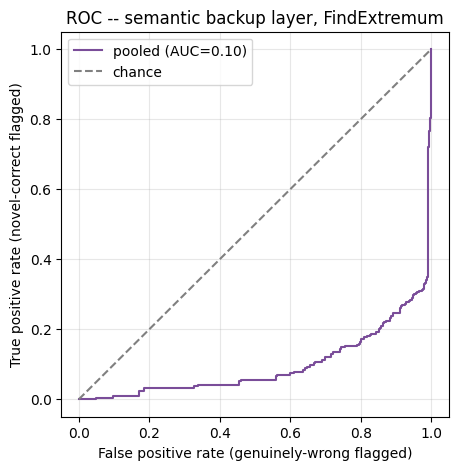

In [ ]:
from sklearn.metrics import roc_curve

y_true_pooled = (pooled["group"] == "novel_correct").astype(int)
y_score_pooled = pooled["similarity"]

fpr, tpr, thresholds = roc_curve(y_true_pooled, y_score_pooled)
pooled_auc = roc_auc_score(y_true_pooled, y_score_pooled)
print(f"Pooled AUC across all {N_BOOTSTRAP_RUNS} runs ({len(pooled)} scored pairs): {pooled_auc:.3f}")

target_tpr = 0.8
idx = np.argmin(np.abs(tpr - target_tpr))
print(f"\nSuggested threshold for ~{target_tpr:.0%} recall on novel-correct: "
      f"{thresholds[idx]:.3f}  (false-positive rate at this point: {fpr[idx]:.3f})")

plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, color="#7a4d99", label=f"pooled (AUC={pooled_auc:.2f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="chance")
plt.xlabel("False positive rate (genuinely-wrong flagged)")
plt.ylabel("True positive rate (novel-correct flagged)")
plt.title(f"ROC -- semantic backup layer, {COMPETENCY}")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(f"{PROJECT_DIR}/semantic_backup_roc.png", dpi=200, bbox_inches="tight")
plt.show()


## 10. Save results


In [ ]:
bootstrap_df.to_csv(f"{PROJECT_DIR}/semantic_backup_bootstrap_summary.csv", index=False)
pooled.to_csv(f"{PROJECT_DIR}/semantic_backup_pooled_scores.csv", index=False)

from google.colab import files
files.download(f"{PROJECT_DIR}/semantic_backup_bootstrap_summary.csv")
files.download(f"{PROJECT_DIR}/semantic_backup_pooled_scores.csv")

print("Saved. Report the AUC mean +/- std from Section 7 and the pooled AUC from")
print("Section 9 as the actual finding -- whichever way it comes out.")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saved. Report the AUC mean +/- std from Section 7 and the pooled AUC from
Section 9 as the actual finding -- whichever way it comes out.
